# Harry Browne's Permanent Portfolio: A Backtest, January 2005 – October 2026

**2270 Financial Modeling · Nova SBE · Moodle Group G**

| | |
|---|---|
| Members | Inês Ferreira, Carolina Faria, Marta Vilarinho, Alex Lukash, Ugo Ribeiro |
| Streamlit application | Link added after deployment |
| GitHub repository | [github.com/UgoBoudjelal/Browne-s-Permanent-Portfolio-](https://github.com/UgoBoudjelal/Browne-s-Permanent-Portfolio-) |

### Abstract

This notebook implements and evaluates the Permanent Portfolio proposed by Browne (1999), an equal-weighted allocation to US equities, long-term US Treasury bonds, gold and Treasury bills. Each sleeve is intended to perform well in a different macroeconomic regime (prosperity, deflation, inflation and recession), so that the portfolio as a whole does not depend on forecasting which regime will prevail. We implement the strategy with three exchange-traded funds (VTI, TLT and GLD) and the three-month Treasury-bill rate, allow weights to drift with relative prices, and restore equal weights whenever a sleeve leaves a 15–35% tolerance band at a month-end review. Over January 2005 to October 2026 (262 monthly observations), the strategy is compared with a constant mix of 60% US equities and 40% US aggregate bonds, the conventional alternative for a conservative investor, and with an all-equity portfolio. All results are expressed in US dollars and are net of transaction costs unless stated otherwise.

### Reproducibility

The notebook executes end to end in a fresh Google Colab session (*Runtime → Run all*) and requires only an internet connection. All data are retrieved programmatically at run time: monthly prices from Yahoo Finance through the `yfinance` library, which is preinstalled in Colab, and the Treasury-bill rate through the public CSV interface of FRED. No API keys, local data files or additional installations are required. Every number, table and figure reported in the prospectus is produced below; the figures are additionally saved as 300-dpi PNG files in the session's working directory, and the tables as CSV files in its `outputs` folder (see the Appendix). Rate-limiting errors from Yahoo Finance are transient and are resolved by re-running after a short pause; should a future `yfinance` release change its interface, the version recorded in Section 1 can be pinned with `!pip -q install yfinance==<version>`.

### Structure and conventions

Sections 1 to 5 document the computational environment, the model parameters and the data pipeline. Sections 6 to 8 present the backtesting engine, its validation and the treatment of implementation costs. Sections 9 to 12 define the performance measures and report the main results, while Sections 13 to 15 contain the sensitivity, crisis-period and robustness analyses. Section 16 discusses the limitations of the study and lists the references and the disclosure of generative-AI use, and the Appendix saves the tables in machine-readable form.

Returns are simple monthly returns expressed in decimals. Yahoo Finance time-stamps each monthly observation on the first calendar day of the month, although the price refers to the month's last close; an observation dated 2008-01-01 is therefore the return for January 2008, and a rebalancing recorded in 2008-01 is executed at the end of January 2008. Means are annualized by multiplying by 12 and volatilities by √12, and beta is reported unannualized.

## 1. Computational Environment

The analysis relies only on libraries that are preinstalled in Google Colab. Their versions are printed to document the environment in which the reported results were produced.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

print("pandas", pd.__version__, "| numpy", np.__version__, "| yfinance", yf.__version__)

pandas 2.2.3 | numpy 2.4.6 | yfinance 0.2.66


## 2. Model Parameters and Assumptions

All inputs of the model are declared in the following cell, so that every result can be regenerated under alternative assumptions by changing a single value. The Streamlit application varies the same parameters.

In [2]:
# Sample period (start inclusive, end exclusive): first return January 2005, last return October 2026
start = '2004-12-01'
end = '2026-11-01'

# Constituents and allocation rule
tickers = ['VTI', 'TLT', 'GLD', 'AGG']           # AGG enters the benchmark only
target_w = np.array([0.25, 0.25, 0.25, 0.25])    # equities, long-term Treasuries, gold, Treasury bills
band_low, band_high = 0.15, 0.35                 # tolerance band around the 25% targets
check_months = list(range(1, 13))                # months in which the band is reviewed (every month-end)

# Benchmark: constant mix of US equities (VTI) and US aggregate bonds (AGG)
w_stocks_bench = 0.60

# Proportional transaction costs per dollar traded, charged on each side of a trade
cost = 0.0005                                    # base case
cost_stress = 0.005                              # stress case

periods = 12                                     # monthly observations per year

### Assumptions

*Sample and data.* The sample comprises 262 monthly returns from January 2005 to October 2026. Its beginning is determined by the inception of GLD in November 2004 and its end by the most recent month for which the Treasury-bill rate is available. Prices are month-end closes adjusted for splits and distributions, so that returns are total returns; fund expense ratios are deducted from net asset value and are therefore already reflected in prices.

*Returns and the risk-free rate.* We work with simple rather than logarithmic returns, since only simple returns aggregate exactly across assets: the return of a portfolio equals the value-weighted average of its constituents' simple returns, a property on which the backtest relies. The cash sleeve earns the three-month Treasury-bill rate (FRED series TB3MS), converted into a monthly return by dividing the previous month's average annual rate by twelve, so that each month earns the rate observable at its start. The same series serves as the risk-free rate in the Sharpe ratio and in the estimation of alpha, which keeps the treatment of cash internally consistent.

*Allocation rule and timing.* The portfolio starts with 25% in each sleeve, after which weights drift with relative prices. At every month-end the weights are compared with a tolerance band of 15–35%, and if any weight lies outside it all four are reset to 25%. Each decision uses only information available at that month-end and is executed at that month's closing prices, so that the new weights earn the following month's return and the simulation is free of look-ahead bias. Reviewing frequently while trading only when deviations become material is consistent with the evidence of Daryanani (2008), who finds that tolerance-band rebalancing of this kind can more than double the benefit of traditional annual rebalancing.

*Benchmarks.* The primary benchmark is a constant mix of 60% US equities (VTI) and 40% US aggregate bonds (AGG). Holding the same equity fund as the Permanent Portfolio ensures that differences in performance reflect the allocation rule rather than the choice of equity index. A constant mix implies monthly rebalancing, so the benchmark is reported both without costs, as an index, and after the same transaction costs as the strategy. An all-equity portfolio (100% VTI) serves as a secondary reference.

*Transaction costs.* Costs are proportional to the value traded and are charged on both purchases and sales in the month of the trade. The base case of 0.05% per dollar traded is calibrated to observed bid–ask spreads, while a stress case of 0.5% tests whether the conclusions survive considerably more expensive execution (Section 8). The initial purchase is not charged and taxes are not modelled.

## 3. Data I: Exchange-Traded Fund Prices

Monthly closing prices are retrieved from Yahoo Finance for the three constituents and for AGG, which enters only the benchmark. The argument `auto_adjust=True` is specified explicitly, because its default has changed across `yfinance` releases and because it determines whether distributions, which are material for TLT and AGG, are reflected in returns. The index is made timezone-naive so that it aligns with the FRED series.

In [3]:
def download_prices(tickers, start, end):
    # Monthly closing prices adjusted for splits and distributions
    df = yf.download(list(tickers), start=start, end=end,
                     interval='1mo', auto_adjust=True, progress=False)
    prices = df['Close'].copy()
    prices.index = prices.index.tz_localize(None)    # align with the timezone-naive FRED dates
    prices.columns.name = None
    return prices

## 4. Data II: Treasury-Bill Rate

The return on cash and the risk-free rate are derived from FRED series TB3MS, the monthly average of the three-month Treasury-bill secondary-market rate in percent per annum, which is retrieved through FRED's public CSV interface with the sample bounds specified in the request. The series is converted into a monthly decimal return and lagged by one month, so that each month earns the rate prevailing at its start. TB3MS is quoted on a discount basis, which slightly understates the investment yield of a bill; treating it as a simple yield is a standard approximation whose effect on the results is small.

In [4]:
def download_tbill(start, end):
    # Monthly return on Treasury bills (FRED TB3MS), lagged to the rate known at the start of each month
    last_month = (pd.Timestamp(end) - pd.DateOffset(months=1)).strftime('%Y-%m-%d')
    url = ('https://fred.stlouisfed.org/graph/fredgraph.csv?id=TB3MS'
           f'&cosd={start}&coed={last_month}')
    tbill = pd.read_csv(url, index_col=0, parse_dates=True, na_values='.')

    rf = tbill['TB3MS'] / 100 / 12    # percent per annum -> monthly decimal return
    rf = rf.shift(1)
    return rf

## 5. Data III: Return Panel, Validation and Summary Statistics

The two sources are merged into a single panel of monthly returns. Data integrity is enforced programmatically rather than assumed: the dates returned by each source are compared with the expected monthly calendar, and any discrepancy halts execution with an explicit error instead of allowing observations to be silently misaligned or discarded. Returns are computed with `pct_change(fill_method=None)`, which preserves a missing price as missing rather than carrying the previous price forward and generating a spurious zero return, and the panel must be complete before the analysis proceeds. It is then inspected for dimensions, coverage, missing values and plausibility, and summarized in the data table reported in the prospectus.

Shape: (262, 5)
Coverage: January 2005 to October 2026
Missing values per series:
AGG    0
GLD    0
TLT    0
VTI    0
rf     0
dtype: int64


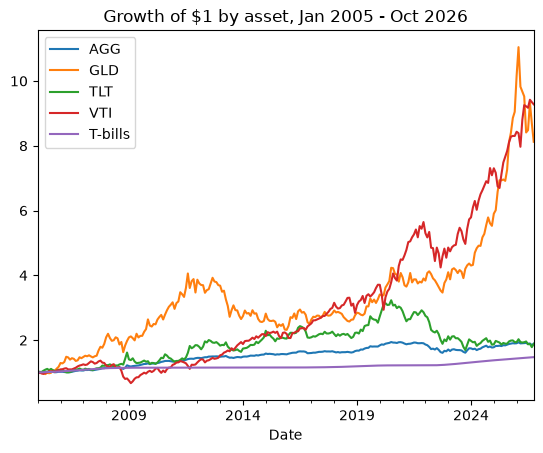

,Source,First month,Last month,Observations
Series,,,,
VTI,Yahoo Finance,Jan 2005,Oct 2026,262
TLT,Yahoo Finance,Jan 2005,Oct 2026,262
GLD,Yahoo Finance,Jan 2005,Oct 2026,262
AGG,Yahoo Finance,Jan 2005,Oct 2026,262
TB3MS (Treasury bills),FRED,Jan 2005,Oct 2026,262


In [5]:
def load_data(start, end, tickers=('VTI', 'TLT', 'GLD', 'AGG')):
    # Monthly simple returns of the ETFs and of Treasury bills, validated against the expected calendar
    prices = download_prices(tickers, start, end)
    rf = download_tbill(start, end)

    expected = list(pd.date_range(start, end, freq='MS', inclusive='left').strftime('%Y-%m-%d'))
    if list(prices.index.strftime('%Y-%m-%d')) != expected:
        raise ValueError('Yahoo Finance dates do not match the expected monthly calendar.')
    if list(rf.index.strftime('%Y-%m-%d')) != expected:
        raise ValueError('FRED dates do not match the expected monthly calendar.')

    rets = prices.pct_change(fill_method=None)     # no forward-filling of missing prices
    rets['rf'] = rf.values
    rets = rets.iloc[1:]                           # the first observation has no return

    if rets.isna().any().any():
        bad_months = list(rets.index[rets.isna().any(axis=1)].strftime('%Y-%m'))
        raise ValueError(f'Missing observations in: {bad_months}')
    return prices, rets


prices, rets = load_data(start, end, tickers)

# Inspection: dimensions, coverage, missing values and a visual check
print("Shape:", rets.shape)
print(f"Coverage: {rets.index[0]:%B %Y} to {rets.index[-1]:%B %Y}")
print("Missing values per series:")
print(rets.isna().sum())
(1 + rets).cumprod().rename(columns={'rf': 'T-bills'}).plot(title=f'Growth of $1 by asset, {rets.index[0]:%b %Y} - {rets.index[-1]:%b %Y}')
plt.show()

# Data summary for the prospectus
rows = []
for col in ['VTI', 'TLT', 'GLD', 'AGG', 'rf']:
    rows.append({'Series': 'TB3MS (Treasury bills)' if col == 'rf' else col,
                 'Source': 'FRED' if col == 'rf' else 'Yahoo Finance',
                 'First month': f'{rets[col].first_valid_index():%b %Y}',
                 'Last month': f'{rets[col].last_valid_index():%b %Y}',
                 'Observations': int(rets[col].notna().sum())})
data_summary = pd.DataFrame(rows).set_index('Series')
display(data_summary)

## 6. Backtesting Engine

The engine tracks the dollar value of each position. Starting from one dollar invested equally across the four sleeves, each position compounds at its own monthly return; the portfolio return is the relative change in total value, and the resulting pre-trade weights are compared with the tolerance band at each review date. When the band is breached, all positions are restored to their target weights and the amount traded, measured as the sum of absolute weight changes (purchases plus sales as a fraction of portfolio value), is recorded as turnover.

An explicit recursion is required because the rebalancing decision is path-dependent: whether the portfolio trades in a given month depends on how far the weights have drifted since the last reset. The familiar fixed-weight expression $r_{p,t} = \sum_i w_i\, r_{i,t}$ implicitly assumes a reset in every period, and Section 7 verifies that the engine reproduces it exactly when rebalancing is forced every month.

In [6]:
def backtest(asset_rets, target_w, band_low, band_high, check_months):
    # Band-rebalanced portfolio with drifting weights.
    # Returns monthly portfolio returns, two-sided turnover and post-trade weights.
    n_months = asset_rets.shape[0]
    values = target_w.copy()                     # position values; initial wealth of $1
    ptf_rets = np.zeros(n_months)
    turnover = np.zeros(n_months)
    weights = np.zeros((n_months, len(target_w)))

    for t in range(n_months):
        old_total = values.sum()
        values = values * (1 + asset_rets.iloc[t].values)
        new_total = values.sum()
        ptf_rets[t] = new_total / old_total - 1
        w = values / new_total                   # pre-trade weights after drift

        # Review at the month-end, using only information available at t
        if asset_rets.index[t].month in check_months and (w.min() < band_low or w.max() > band_high):
            turnover[t] = np.sum(np.abs(target_w - w))
            values = target_w * new_total

        weights[t] = values / values.sum()       # post-trade weights, held over the next month

    return ptf_rets, turnover, weights

## 7. Simulation Results and Validation

The simulation yields the monthly return series of the Permanent Portfolio before costs, which is stored together with the benchmark returns, the risk-free rate and turnover. Three validations are applied. First, with rebalancing disabled, terminal wealth must equal the buy-and-hold value $\sum_i w_i \prod_t (1 + r_{i,t})$, which tests the drift mechanics. Second, when rebalancing is forced every month, the simulated returns must coincide with the constant-weight returns $\sum_i w_i\, r_{i,t}$. Third, pre-trade weights are reconstructed independently of the engine, by compounding the previous month's post-trade weights with the current month's returns and renormalizing, and rebalancing must occur in exactly those review months in which one of these weights lies outside the band. All comparisons of floating-point quantities use a numerical tolerance rather than exact equality.

Rebalancing dates (7): ['2008-01', '2009-02', '2011-01', '2016-11', '2021-04', '2024-12', '2026-01']
Validation 1, buy-and-hold equivalence (5.190096 vs 5.190096): True
Validation 2, constant-weight equivalence: True
Validation 3, rebalancing coincides with band breaches: True

Pre-trade weights at each rebalancing date:


,Equities,Long-term Treasuries,Gold,Treasury bills
Date,,,,
2008-01-01,0.215,0.217,0.368,0.200
2009-02-01,0.149,0.303,0.274,0.274
2011-01-01,0.358,0.184,0.267,0.191
2016-11-01,0.359,0.292,0.161,0.188
2021-04-01,0.353,0.216,0.252,0.179
2024-12-01,0.300,0.150,0.311,0.239
2026-01-01,0.233,0.204,0.359,0.204


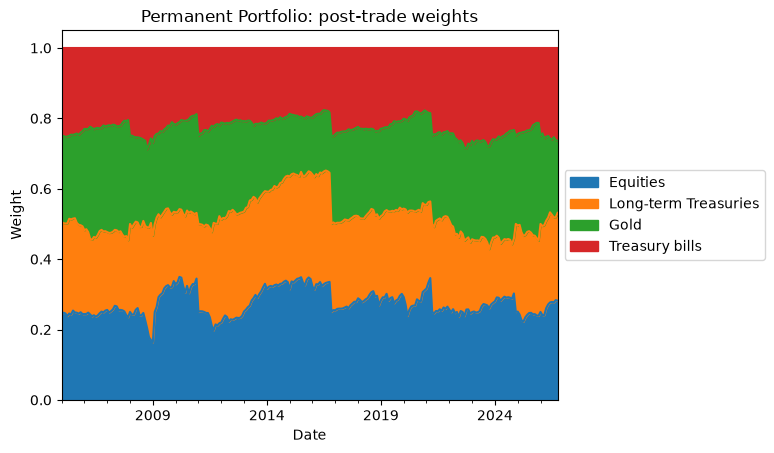

In [7]:
pp_assets = rets[['VTI', 'TLT', 'GLD', 'rf']]          # ordered as target_w
pp_rets, pp_turnover, pp_weights = backtest(pp_assets, target_w, band_low, band_high, check_months)

results = pd.DataFrame(index=rets.index)
results['pp'] = pp_rets                                                                    # before costs
results['bench_6040'] = w_stocks_bench * rets['VTI'] + (1 - w_stocks_bench) * rets['AGG']   # constant mix
results['stocks'] = rets['VTI']
results['rf'] = rets['rf']
results['turnover'] = pp_turnover

rebalance_dates = list(results.index[results['turnover'] > 0].strftime('%Y-%m'))
print(f"Rebalancing dates ({len(rebalance_dates)}):", rebalance_dates)

# Validation 1: without rebalancing, terminal wealth equals the buy-and-hold value
r_never, to_never, _ = backtest(pp_assets, target_w, band_low, band_high, check_months=[])
loop_value = np.prod(1 + r_never)
buy_and_hold = np.sum(target_w * (1 + pp_assets).prod().values)
print(f"Validation 1, buy-and-hold equivalence ({loop_value:.6f} vs {buy_and_hold:.6f}):",
      abs(loop_value - buy_and_hold) < 1e-9)

# Validation 2: with a reset every month, returns equal the constant-weight returns
r_monthly, _, _ = backtest(pp_assets, target_w, 0.25, 0.25, check_months=list(range(1, 13)))
formula = 0.25 * (rets['VTI'] + rets['TLT'] + rets['GLD'] + rets['rf'])
print("Validation 2, constant-weight equivalence:",
      np.max(np.abs(r_monthly - formula.values)) < 1e-9)

# Validation 3: rebalancing occurs exactly in the review months with a band breach
weights_after = pd.DataFrame(pp_weights, index=rets.index,
                             columns=['Equities', 'Long-term Treasuries', 'Gold', 'Treasury bills'])
weights_before = weights_after.shift(1).fillna(0.25) * (1 + pp_assets.values)
weights_before = weights_before.div(weights_before.sum(axis=1), axis=0)
breach = ((weights_before.min(axis=1) < band_low) | (weights_before.max(axis=1) > band_high)) \
         & weights_before.index.month.isin(check_months)
print("Validation 3, rebalancing coincides with band breaches:",
      (breach == (results['turnover'] > 0)).all())

print("\nPre-trade weights at each rebalancing date:")
display(weights_before[breach].round(3))

ax = weights_after.plot.area(title='Permanent Portfolio: post-trade weights')
ax.set_ylabel('Weight')
ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.savefig('fig_weights.png', dpi=300, bbox_inches='tight')
plt.show()


### External check against published returns

As an external check, calendar-year returns computed from our data are compared with the market-price total returns published by the issuers for 2022–2025 (Vanguard for VTI and iShares for TLT, accessed 24 November 2026). The two sources can differ slightly in the date and price at which distributions are assumed to be reinvested, so a tolerance of 0.5 percentage points is allowed; the largest difference observed is about 0.1 points. Because distributions account for a large share of TLT's total return, the agreement confirms that the adjusted prices include them. GLD pays no distributions, so its adjusted and unadjusted prices coincide and the comparison would add little. The cell also reports the calendar-year returns of every series and the range of the monthly Treasury-bill return, a plausibility check on the unit conversion in Section 4.

In [8]:
# Calendar-year returns of every series (2026 covers January to October)
calendar_returns = (1 + rets).groupby(rets.index.year).prod() - 1
display(calendar_returns.round(4))
print(f"Monthly T-bill return: minimum {rets['rf'].min():.4%}, maximum {rets['rf'].max():.4%}")

# Issuers' published market-price total returns, read from the Vanguard (VTI) and iShares (TLT)
# fund pages on 24 November 2026
published = pd.DataFrame({
    'VTI': {2022: -0.1951, 2023: 0.2611, 2024: 0.2371, 2025: 0.1710},
    'TLT': {2022: -0.3125, 2023: 0.0277, 2024: -0.0806, 2025: 0.0425},
})
ours = calendar_returns.loc[published.index, published.columns]

comparison = pd.DataFrame(index=published.index)
for t in published.columns:
    comparison[f'{t}: our data (%)'] = 100 * ours[t]
    comparison[f'{t}: issuer (%)'] = 100 * published[t]
    comparison[f'{t}: difference (pp)'] = 100 * (ours[t] - published[t])
comparison.index.name = 'Year'
display(comparison.round(2))

max_gap = 100 * (ours - published).abs().max().max()
print(f"External check, largest difference {max_gap:.2f} pp (tolerance 0.5 pp):", max_gap < 0.5)


,AGG,GLD,TLT,VTI,rf
Date,,,,,
2005,0.0226,0.1776,0.0860,0.0630,0.0305
2006,0.0390,0.2255,0.0071,0.1570,0.0475
2007,0.0659,0.3045,0.1030,0.0537,0.0460
2008,0.0790,0.0492,0.3395,-0.3699,0.0162
2009,0.0297,0.2403,-0.2181,0.2890,0.0015
2010,0.0636,0.2927,0.0901,0.1743,0.0013
2011,0.0770,0.0957,0.3400,0.0097,0.0006
2012,0.0375,0.0660,0.0241,0.1645,0.0008
2013,-0.0198,-0.2833,-0.1338,0.3345,0.0006


Monthly T-bill return: minimum 0.0008%, maximum 0.4450%


,VTI: our data (%),VTI: issuer (%),VTI: difference (pp),TLT: our data (%),TLT: issuer (%),TLT: difference (pp)
Year,,,,,,
2022,-19.52,-19.51,-0.01,-31.23,-31.25,0.02
2023,26.05,26.11,-0.06,2.77,2.77,-0.00
2024,23.81,23.71,0.10,-8.05,-8.06,0.01
2025,17.10,17.10,-0.00,4.25,4.25,-0.00


External check, largest difference 0.10 pp (tolerance 0.5 pp): True


## 8. Implementation Costs

Rebalancing incurs a proportional cost on every dollar bought and sold. Because turnover already aggregates both sides of each trade, the cost borne in a month equals turnover multiplied by the cost rate, and it is deducted from that month's return.

The base-case rate of 0.05% per dollar traded is calibrated to the market microstructure of the instruments. VTI, TLT and GLD trade at thirty-day median bid–ask spreads of about 0.01% ([Vanguard](https://investor.vanguard.com/investment-products/mutual-funds/profile/VTI); [iShares](https://www.ishares.com/us/products/239454/ishares-20-year-treasury-bond-etf); [State Street](https://www.ssga.com/us/en/institutional/etfs/spdr-gold-shares-gld)), so crossing half the spread costs roughly 0.005%. The base case allows ten times this amount, to account for commissions and for the wider spreads that prevail in the volatile months in which rebalancing tends to occur. The stress case of 0.5% corresponds to the conservative all-in cost assumed in the course materials for a retail investor trading an individual stock and is deliberately pessimistic for these instruments; it establishes whether the conclusions hold when execution costs are an order of magnitude above the base case. Section 13 extends the analysis to the full range from 0% to 1%.

The benchmark is not costless either. Maintaining a constant mix requires monthly rebalancing: after a month in which equities return $r^{s}_t$ and the benchmark $r^{b}_t$, the equity weight has drifted to $0.6\,(1 + r^{s}_t)/(1 + r^{b}_t)$, and restoring it to 60% requires trading the difference in each of the two funds, so that turnover equals twice the absolute drift. The benchmark is therefore evaluated both before and after costs.

In [9]:
# Permanent Portfolio net of costs: base case and stress case
results['pp_net'] = results['pp'] - results['turnover'] * cost
results['pp_net_stress'] = results['pp'] - results['turnover'] * cost_stress

n_rebalances = int((results['turnover'] > 0).sum())
n_years = len(results) / periods
annual_turnover = results['turnover'].sum() / n_years
print(f"Rebalancing events: {n_rebalances} over {n_years:.1f} years")
print(f"Average annual turnover: {annual_turnover:.2%}")
print(f"Average annual cost: {annual_turnover * cost:.3%} (base case, {cost:.2%} per side), "
      f"{annual_turnover * cost_stress:.3%} (stress case, {cost_stress:.2%} per side)")

# Benchmark turnover: twice the monthly drift of the equity weight away from 60%
w_stocks_drifted = w_stocks_bench * (1 + rets['VTI']) / (1 + results['bench_6040'])
results['bench_turnover'] = 2 * (w_stocks_drifted - w_stocks_bench).abs()
results['bench_6040_net'] = results['bench_6040'] - results['bench_turnover'] * cost
bench_annual_turnover = results['bench_turnover'].sum() / n_years
print(f"\n60/40 benchmark: average annual turnover {bench_annual_turnover:.2%}; average annual cost "
      f"{bench_annual_turnover * cost:.3%} (base case), {bench_annual_turnover * cost_stress:.3%} (stress case)")

Rebalancing events: 7 over 21.8 years
Average annual turnover: 7.51%
Average annual cost: 0.004% (base case, 0.05% per side), 0.038% (stress case, 0.50% per side)

60/40 benchmark: average annual turnover 19.13%; average annual cost 0.010% (base case), 0.096% (stress case)


## 9. Performance Measures

Performance is evaluated with the measures prescribed by the course formula sheet, complemented by a test of the statistical significance of alpha and by drawdown statistics. Let $r_t$ denote the monthly return of the portfolio, $r^b_t$ that of the benchmark, $r^f_t$ the risk-free rate and $T$ the number of months. The annualized mean return is $12\,\bar r$, the annualized volatility is $\sqrt{12}\,\sigma(r)$ and the compound annual growth rate is $\left[\prod_t (1 + r_t)\right]^{12/T} - 1$. The Sharpe ratio (Sharpe, 1966, 1994) is the mean excess return per unit of excess-return volatility, annualized by the factor $\sqrt{12}$.

Systematic exposure and risk-adjusted performance relative to the benchmark are measured with the single-index regression of Jensen (1968),

$$r_t - r^f_t = \alpha + \beta\,(r^b_t - r^f_t) + \varepsilon_t ,$$

whose coefficients are computed in closed form as $\beta = \operatorname{cov}(x, y)/\operatorname{var}(x)$ and $\alpha = \bar y - \beta \bar x$, where $y_t$ and $x_t$ denote the excess returns of the portfolio and of the benchmark. Alpha is annualized by multiplying by twelve, while beta is unitless and reported as estimated. Since $\alpha$ is estimated from a finite and noisy sample, we test whether it differs from zero with the t-statistic of the intercept, $t = \hat\alpha / SE(\hat\alpha)$, where

$$SE(\hat\alpha) = \sqrt{s^2 \left( \frac{1}{T} + \frac{\bar x^2}{\sum_t (x_t - \bar x)^2} \right)}, \qquad s^2 = \frac{1}{T - 2} \sum_t \hat\varepsilon_t^{\,2} .$$

The statistic assumes serially uncorrelated and homoskedastic residuals, and absolute values above approximately two indicate significance at the 5% level.

Active performance is described by the tracking error, the annualized volatility of $r_t - r^b_t$, and by the information ratio, the annualized mean of $r_t - r^b_t$ divided by the tracking error (Grinold and Kahn, 2000). Finally, with cumulative wealth $P_t$ indexed to one at the start of the sample and high-water mark $HWM_t = \max_{s \le t} P_s$, the drawdown is $DD_t = (HWM_t - P_t)/HWM_t$ and the maximum drawdown is $\max_t DD_t$. Indexing wealth to one in the month preceding the first return ensures that a loss in the first month is recorded as a drawdown and that cumulative performance is plotted from unity.

In [10]:
def wealth_index(r):
    # Cumulative wealth indexed to 1 in the month preceding the first return
    wealth = (1 + r).cumprod()
    start_date = wealth.index[0] - pd.DateOffset(months=1)
    return pd.concat([pd.Series([1.0], index=[start_date]), wealth])


def max_drawdown(r):
    # Maximum of DD_t = (HWM_t - P_t) / HWM_t, reported as a positive number
    p = wealth_index(r)
    hwm = p.cummax()
    return ((hwm - p) / hwm).max()


def performance(r, rf, bench=None, periods=12):
    # Annualized performance measures from monthly simple returns; beta is not annualized.
    # With a benchmark, adds beta, alpha, the t-statistic of alpha, tracking error and information ratio.
    ex = r - rf
    out = {
        'Annualized average return': r.mean() * periods,
        'Compound annual return': (1 + r).prod() ** (periods / len(r)) - 1,
        'Annualized volatility': r.std() * np.sqrt(periods),
        'Sharpe ratio': ex.mean() / ex.std() * np.sqrt(periods),
        'Beta': np.nan,
        'Annualized alpha': np.nan,
        'Alpha t-statistic': np.nan,
        'Annualized tracking error': np.nan,
        'Information ratio': np.nan,
        'Maximum drawdown': max_drawdown(r),
        'Growth of $1': (1 + r).prod(),
    }
    if bench is not None:
        bench_ex = bench - rf
        beta = ex.cov(bench_ex) / bench_ex.var()
        alpha = ex.mean() - beta * bench_ex.mean()
        resid = ex - alpha - beta * bench_ex
        se_alpha = np.sqrt(resid.var(ddof=2) * (1 / len(r) + bench_ex.mean() ** 2
                                                / ((bench_ex - bench_ex.mean()) ** 2).sum()))
        active = r - bench
        out['Beta'] = beta
        out['Annualized alpha'] = alpha * periods
        out['Alpha t-statistic'] = alpha / se_alpha
        out['Annualized tracking error'] = active.std() * np.sqrt(periods)
        out['Information ratio'] = active.mean() / active.std() * np.sqrt(periods)
    return out


def format_table(table):
    # Presentation only: percentages and ratios to two decimals, '-' where a measure does not apply
    pct_rows = ['Annualized average return', 'Compound annual return', 'Annualized volatility',
                'Annualized alpha', 'Annualized tracking error', 'Maximum drawdown', 'Annual cost drag']
    formatted = {}
    for row in table.index:
        fmt = '{:.2%}' if row in pct_rows else '{:.2f}'
        formatted[row] = ['-' if pd.isna(v) else fmt.format(v) for v in table.loc[row]]
    return pd.DataFrame.from_dict(formatted, orient='index', columns=table.columns)

## 10. Performance Evaluation

The first table reports the complete set of measures for the Permanent Portfolio under base-case and stress-case costs, for the 60/40 benchmark before and after costs, and for the all-equity portfolio. Beta, alpha, tracking error and the information ratio of the Permanent Portfolio are measured against the frictionless benchmark, and the second table repeats them against the all-equity portfolio. The regression estimates are verified with NumPy's least-squares routine `np.polyfit`, whose coefficient covariance matrix independently delivers the standard error of the intercept.

In [11]:
perf_table = pd.DataFrame({
    'Permanent Portfolio': performance(results['pp_net'], results['rf'], results['bench_6040']),
    'PP, stress costs': performance(results['pp_net_stress'], results['rf'], results['bench_6040']),
    '60/40': performance(results['bench_6040'], results['rf']),
    '60/40, net of costs': performance(results['bench_6040_net'], results['rf']),
    'All equity (VTI)': performance(results['stocks'], results['rf']),
})
print(f"Performance, {rets.index[0]:%B %Y} to {rets.index[-1]:%B %Y}. Permanent Portfolio net of base-case "
      f"({cost:.2%}) and stress-case ({cost_stress:.2%}) costs per side; 60/40 without and with base-case costs.")
print("Beta, alpha, tracking error and information ratio relative to the frictionless 60/40.")
display(format_table(perf_table))

perf_vs_stocks = pd.DataFrame({
    'Permanent Portfolio vs all equity': performance(results['pp_net'], results['rf'], results['stocks'])
}).loc[['Beta', 'Annualized alpha', 'Alpha t-statistic', 'Annualized tracking error', 'Information ratio']]
print("Relative to the all-equity portfolio:")
display(format_table(perf_vs_stocks))

# Validation of the regression estimates with NumPy's least-squares fit
x = (results['bench_6040'] - results['rf']).values
y = (results['pp_net'] - results['rf']).values
(ols_beta, ols_alpha), ols_cov = np.polyfit(x, y, 1, cov=True)
pp_col = 'Permanent Portfolio'
print("Validation 4, beta equals the OLS slope:",
      abs(ols_beta - perf_table.loc['Beta', pp_col]) < 1e-9)
print("Validation 5, alpha equals the OLS intercept:",
      abs(ols_alpha * periods - perf_table.loc['Annualized alpha', pp_col]) < 1e-9)
print("Validation 6, t-statistic matches the OLS standard error:",
      abs(ols_alpha / np.sqrt(ols_cov[1, 1]) - perf_table.loc['Alpha t-statistic', pp_col]) < 1e-6)
print("Validation 7, wealth index starts at 1:",
      abs(wealth_index(results['pp_net']).iloc[0] - 1) < 1e-9)
print("Validation 8, costs never increase returns:",
      (results['pp_net'] <= results['pp'] + 1e-12).all()
      and (results['pp_net_stress'] <= results['pp_net'] + 1e-12).all()
      and (results['bench_6040_net'] <= results['bench_6040'] + 1e-12).all())

Performance, January 2005 to October 2026. Permanent Portfolio net of base-case (0.05%) and stress-case (0.50%) costs per side; 60/40 without and with base-case costs.
Beta, alpha, tracking error and information ratio relative to the frictionless 60/40.


,Permanent Portfolio,"PP, stress costs",60/40,"60/40, net of costs",All equity (VTI)
Annualized average return,7.61%,7.58%,8.06%,8.05%,11.42%
Compound annual return,7.60%,7.56%,7.85%,7.84%,10.74%
Annualized volatility,7.32%,7.32%,9.73%,9.73%,15.26%
Sharpe ratio,0.80,0.80,0.64,0.64,0.63
Beta,0.49,0.49,-,-,-
Annualized alpha,2.78%,2.74%,-,-,-
Alpha t-statistic,2.30,2.27,-,-,-
Annualized tracking error,7.46%,7.46%,-,-,-
Information ratio,-0.06,-0.06,-,-,-
Maximum drawdown,16.36%,16.36%,32.32%,32.34%,50.84%


Relative to the all-equity portfolio:


,Permanent Portfolio vs all equity
Beta,0.26
Annualized alpha,3.28%
Alpha t-statistic,2.48
Annualized tracking error,12.76%
Information ratio,-0.30


Validation 4, beta equals the OLS slope: True
Validation 5, alpha equals the OLS intercept: True
Validation 6, t-statistic matches the OLS standard error: True
Validation 7, wealth index starts at 1: True
Validation 8, costs never increase returns: True


Alpha and the information ratio need not share the same sign. Alpha compares the portfolio with a combination of the benchmark and Treasury bills that has the same beta, whereas the information ratio compares it with the benchmark itself. A portfolio whose beta is well below one can therefore earn less than the benchmark, and hence have a negative information ratio, while still earning more than its systematic exposure alone would predict, and hence have a positive alpha. Comparing the first two columns isolates the sensitivity of the conclusions to execution costs, and comparing the two benchmark columns shows the cost of maintaining a constant mix.

## 11. Cumulative Performance

The figure plots the growth of one dollar invested at the end of December 2004 in the Permanent Portfolio, net of base-case costs, in the 60/40 benchmark and in the all-equity portfolio. All series are indexed to one at the start of the sample, as required by the assignment.

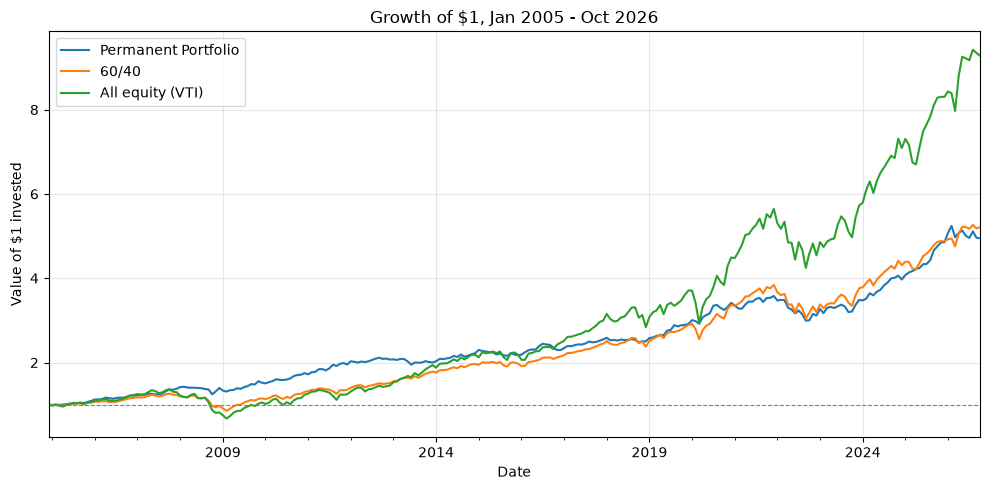

In [12]:
wealth = pd.DataFrame({
    'Permanent Portfolio': wealth_index(results['pp_net']),
    '60/40': wealth_index(results['bench_6040']),
    'All equity (VTI)': wealth_index(results['stocks']),
})

fig, ax = plt.subplots(figsize=(10, 5))
wealth.plot(ax=ax)
ax.axhline(1, color='grey', linewidth=0.8, linestyle='--')
ax.set_title(f'Growth of $1, {rets.index[0]:%b %Y} - {rets.index[-1]:%b %Y}')
ax.set_xlabel('Date')
ax.set_ylabel('Value of $1 invested')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('fig_cumulative_performance.png', dpi=300)
plt.show()

## 12. Drawdowns and the Risk–Return Trade-off

The first figure plots each portfolio's drawdown from its running maximum; the trough of each series corresponds to the maximum drawdown reported in Section 10. The second locates the portfolios and their constituents in mean–volatility space and illustrates the diversification mechanism on which the strategy rests: positions in assets whose correlations are low and regime-dependent combine into a portfolio whose volatility lies well below that of each of its risky constituents.

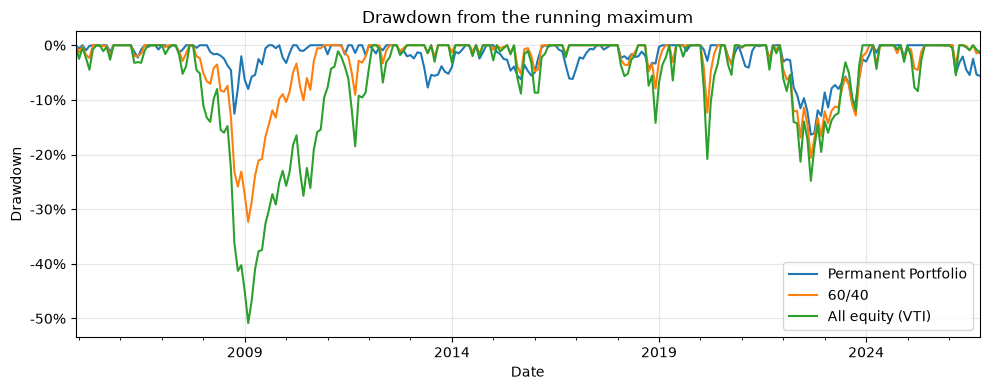

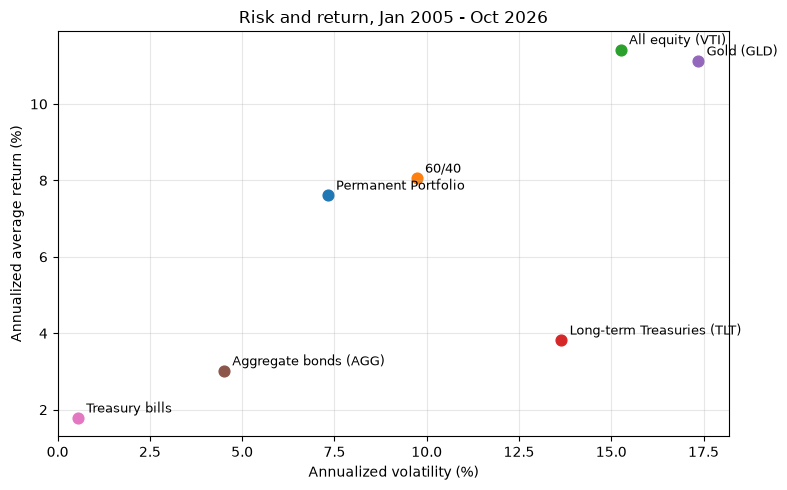

In [13]:
# Drawdowns from the running maximum (shown as negative values)
drawdowns = -(wealth.cummax() - wealth) / wealth.cummax()

fig, ax = plt.subplots(figsize=(10, 4))
drawdowns.plot(ax=ax)
ax.set_title('Drawdown from the running maximum')
ax.set_xlabel('Date')
ax.set_ylabel('Drawdown')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('fig_drawdowns.png', dpi=300)
plt.show()

# Annualized mean return against annualized volatility, in percent
series = {'Permanent Portfolio': results['pp_net'], '60/40': results['bench_6040'],
          'All equity (VTI)': rets['VTI'], 'Long-term Treasuries (TLT)': rets['TLT'], 'Gold (GLD)': rets['GLD'],
          'Aggregate bonds (AGG)': rets['AGG'], 'Treasury bills': rets['rf']}
fig, ax = plt.subplots(figsize=(8, 5))
for name in series:
    vol = 100 * series[name].std() * np.sqrt(periods)
    ret = 100 * series[name].mean() * periods
    ax.scatter(vol, ret, s=60)
    ax.annotate(name, (vol, ret), textcoords='offset points', xytext=(6, 4), fontsize=9)
ax.set_title(f'Risk and return, {rets.index[0]:%b %Y} - {rets.index[-1]:%b %Y}')
ax.set_xlabel('Annualized volatility (%)')
ax.set_ylabel('Annualized average return (%)')
ax.set_xlim(left=0)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('fig_risk_return.png', dpi=300)
plt.show()

## 13. Sensitivity to Transaction Costs

The table reports the performance of the Permanent Portfolio for cost rates between 0% and 1% per dollar traded, with the base and stress cases labelled. Because costs enter returns linearly, alpha is an affine function of the cost rate, $\alpha(c) = \alpha(0) - k\,c$, where the constant $k$ depends on turnover and on its covariance with benchmark returns. The break-even cost $c^{*}$ at which alpha vanishes therefore follows from two evaluations of the model, $c^{*} = \alpha(0) / [\alpha(0) - \alpha(1)]$. Its magnitude relative to observed spreads indicates how much of the strategy's risk-adjusted performance is exposed to implementation frictions.

In [14]:
cost_levels = [0, 0.0005, 0.001, 0.0025, 0.005, 0.01]
sensitivity = pd.DataFrame()
for c in cost_levels:
    net = results['pp'] - results['turnover'] * c
    m = performance(net, results['rf'], results['bench_6040'])
    m['Annual cost drag'] = annual_turnover * c
    label = f'{c:.2%}'
    if abs(c - cost) < 1e-12:
        label += ' (base case)'
    if abs(c - cost_stress) < 1e-12:
        label += ' (stress case)'
    sensitivity[label] = pd.Series(m)

rows_shown = ['Annual cost drag', 'Annualized average return', 'Compound annual return', 'Sharpe ratio',
              'Annualized alpha', 'Information ratio', 'Maximum drawdown']
print("Permanent Portfolio by cost rate per side (alpha and information ratio relative to the 60/40):")
display(format_table(sensitivity.loc[rows_shown]))

# Break-even cost rate: alpha is linear in the cost rate, so two evaluations determine it
alpha_no_cost = performance(results['pp'], results['rf'], results['bench_6040'])['Annualized alpha']
alpha_full_cost = performance(results['pp'] - results['turnover'] * 1.0,
                              results['rf'], results['bench_6040'])['Annualized alpha']
if alpha_no_cost > 0:
    breakeven = alpha_no_cost / (alpha_no_cost - alpha_full_cost)
    print(f"Break-even cost rate: {breakeven:.1%} per dollar traded "
          f"(base case {cost:.2%}, stress case {cost_stress:.2%}).")
else:
    print("Alpha before costs is not positive, so no break-even cost rate is defined.")

Permanent Portfolio by cost rate per side (alpha and information ratio relative to the 60/40):


,0.00%,0.05% (base case),0.10%,0.25%,0.50% (stress case),1.00%
Annual cost drag,0.00%,0.00%,0.01%,0.02%,0.04%,0.08%
Annualized average return,7.62%,7.61%,7.61%,7.60%,7.58%,7.54%
Compound annual return,7.60%,7.60%,7.59%,7.58%,7.56%,7.52%
Sharpe ratio,0.80,0.80,0.80,0.80,0.80,0.79
Annualized alpha,2.78%,2.78%,2.77%,2.76%,2.74%,2.70%
Information ratio,-0.06,-0.06,-0.06,-0.06,-0.06,-0.07
Maximum drawdown,16.36%,16.36%,16.36%,16.36%,16.36%,16.36%


Break-even cost rate: 34.4% per dollar traded (base case 0.05%, stress case 0.50%).


## 14. Behaviour in Equity Market Crises

Since the strategy is intended for investors who cannot tolerate large losses, its behaviour during equity crises is central to its evaluation. We examine five episodes: the global financial crisis of 2007–09, the euro-area sovereign debt and US debt-ceiling crisis of 2011, the sell-off of the fourth quarter of 2018, the COVID-19 crash of 2020 and the inflation and interest-rate shock of 2022. To limit discretion in dating, each episode is specified only by a broad search window, within which the equity trough is identified as the lowest month-end of VTI and the equity peak as the highest preceding month-end. For each episode we report the return of every portfolio from the equity peak to the equity trough and the time it took to recover, measured as the number of months from the equity peak to the first month-end after the trough at which the portfolio had regained its value at the peak. A portfolio that stood at or above that value at the trough is assigned zero, and one that has not recovered by the end of the sample is reported as missing. Validation 9 confirms that the two tables are mutually consistent: a portfolio that lost value between the peak and the trough cannot have recovered before the trough. The summary statistics are computed from these tables and therefore update with the data.

Return from equity peak to equity trough:


,Equity peak,Equity trough,"Months, peak to trough",Permanent Portfolio,60/40,All equity (VTI)
Episode,,,,,,
Financial crisis (2007-09),Oct 2007,Feb 2009,16,-3.5%,-32.3%,-50.8%
Debt crises (2011),Apr 2011,Sep 2011,5,4.1%,-9.1%,-17.6%
Q4 2018 sell-off,Sep 2018,Dec 2018,3,-1.5%,-7.8%,-14.2%
COVID-19 crash (2020),Dec 2019,Mar 2020,3,0.0%,-11.7%,-20.8%
Rate shock (2022),Dec 2021,Sep 2022,9,-16.4%,-20.6%,-24.8%


Months from the equity peak to recovery (0 = at or above its peak value at the trough; NaN = not recovered by the end of the sample):


,Permanent Portfolio,60/40,All equity (VTI)
Episode,,,
Financial crisis (2007-09),19,38,53
Debt crises (2011),0,9,10
Q4 2018 sell-off,4,6,7
COVID-19 crash (2020),0,6,7
Rate shock (2022),27,26,24


Validation 9, recovery times consistent with peak-to-trough returns: True

The Permanent Portfolio outperformed the 60/40 in 5 of 5 episodes.
Mean return across episodes: Permanent Portfolio -3.4%, 60/40 -16.3%, All equity (VTI) -25.7%
Worst episode for the Permanent Portfolio: Rate shock (2022) (-16.4%).
Mean months from equity peak to recovery (unrecovered episodes excluded): Permanent Portfolio 10.0, 60/40 17.0, All equity (VTI) 20.2


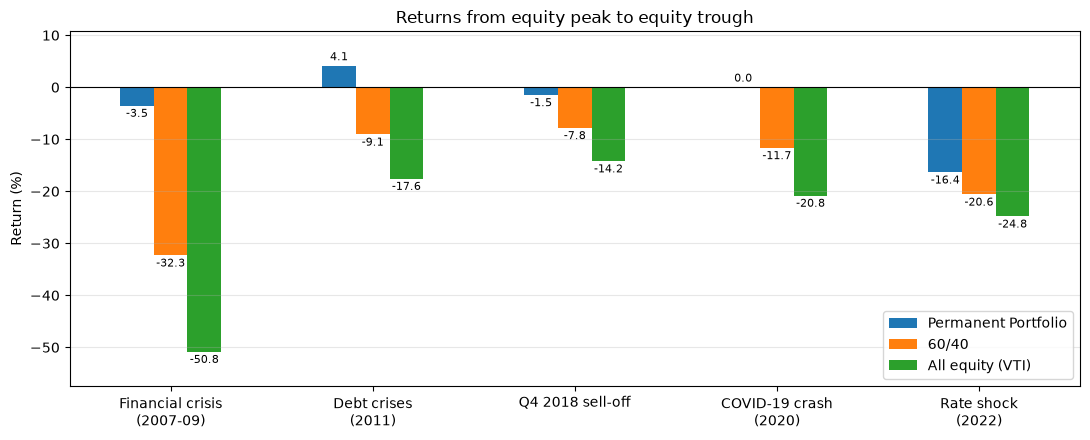

In [15]:
crisis_ranges = {
    'Financial crisis (2007-09)': ('2007-01', '2009-12'),
    'Debt crises (2011)': ('2011-01', '2011-12'),
    'Q4 2018 sell-off': ('2018-07', '2019-03'),
    'COVID-19 crash (2020)': ('2019-10', '2020-12'),
    'Rate shock (2022)': ('2021-10', '2022-12'),
}
portfolios = {'Permanent Portfolio': wealth_index(results['pp_net']),
              '60/40': wealth_index(results['bench_6040']),
              'All equity (VTI)': wealth_index(results['stocks'])}
stock_wealth = portfolios['All equity (VTI)']
dates = list(stock_wealth.index)


def months_to_recover(wealth, peak, trough):
    # Months from the equity peak to the first month-end after the trough at which the portfolio
    # has regained its value at the peak; 0 if it stands at or above that value at the trough
    dates = list(wealth.index)
    peak_value = wealth.loc[peak]
    if wealth.loc[trough] >= peak_value:
        return 0
    for i in range(dates.index(trough) + 1, len(dates)):
        if wealth.iloc[i] >= peak_value:
            return i - dates.index(peak)
    return np.nan            # not recovered by the end of the sample


crisis_rows = []
recovery_rows = []
for name in crisis_ranges:
    first, last = crisis_ranges[name]
    window = stock_wealth.loc[first:last]
    trough = window.idxmin()                    # equity trough within the search window
    peak = window.loc[:trough].idxmax()         # equity peak preceding the trough
    if peak == trough:
        print(f"{name}: no equity decline within the search window; episode omitted.")
        continue
    row = {'Episode': name, 'Equity peak': f'{peak:%b %Y}', 'Equity trough': f'{trough:%b %Y}',
           'Months, peak to trough': dates.index(trough) - dates.index(peak)}
    recovery = {'Episode': name}
    for p in portfolios:
        row[p] = portfolios[p].loc[trough] / portfolios[p].loc[peak] - 1
        recovery[p] = months_to_recover(portfolios[p], peak, trough)
    crisis_rows.append(row)
    recovery_rows.append(recovery)

crisis_table = pd.DataFrame(crisis_rows).set_index('Episode')
recovery_table = pd.DataFrame(recovery_rows).set_index('Episode')
names = list(portfolios)

shown = crisis_table.copy()
for p in names:
    shown[p] = [f'{v:.1%}' for v in crisis_table[p]]
print("Return from equity peak to equity trough:")
display(shown)
print("Months from the equity peak to recovery (0 = at or above its peak value at the trough; "
      "NaN = not recovered by the end of the sample):")
display(recovery_table)

# Validation 9: a portfolio below its peak value at the trough can only recover after the trough
consistent = True
for name in crisis_table.index:
    for p in names:
        if crisis_table.loc[name, p] < 0:
            months = recovery_table.loc[name, p]
            consistent = consistent and (pd.isna(months) or months > crisis_table.loc[name, 'Months, peak to trough'])
        else:
            consistent = consistent and recovery_table.loc[name, p] == 0
print("Validation 9, recovery times consistent with peak-to-trough returns:", consistent)

better = int((crisis_table['Permanent Portfolio'] > crisis_table['60/40']).sum())
worst = crisis_table['Permanent Portfolio'].idxmin()
print(f"\nThe Permanent Portfolio outperformed the 60/40 in {better} of {len(crisis_table)} episodes.")
print("Mean return across episodes: " + ", ".join(f"{p} {crisis_table[p].mean():.1%}" for p in names))
print(f"Worst episode for the Permanent Portfolio: {worst} ({crisis_table.loc[worst, 'Permanent Portfolio']:.1%}).")
print("Mean months from equity peak to recovery (unrecovered episodes excluded): " +
      ", ".join(f"{p} {recovery_table[p].mean():.1f}" for p in names))

fig, ax = plt.subplots(figsize=(11, 4.5))
(100 * crisis_table[names]).plot.bar(ax=ax, rot=0)
for bars in ax.containers:
    ax.bar_label(bars, fmt='%.1f', fontsize=8, padding=2)          # value of each bar, in percent
ax.set_xticklabels([name.replace(' (', '\n(') for name in crisis_table.index])
ax.axhline(0, color='black', linewidth=0.8)
ax.margins(y=0.12)
ax.set_title('Returns from equity peak to equity trough')
ax.set_xlabel('')
ax.set_ylabel('Return (%)')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('fig_crisis_returns.png', dpi=300)
plt.show()


The 2022 episode is the most demanding test of the strategy's design. Equities and long-term Treasuries declined together as inflation and policy rates rose, so the negative stock–bond correlation on which a 60/40 portfolio relies for protection was absent, and losses could only be cushioned by assets outside the stock–bond universe. The Permanent Portfolio holds two such assets, gold and Treasury bills, but its long-term Treasury sleeve fell further than equities that year, so the protection was only partial: the episode coincides with the strategy's maximum drawdown, its loss was only moderately smaller than that of the 60/40, and it was the slowest of the three portfolios to regain its value at the equity peak, since its smaller equity allocation captured less of the strong equity rebound of 2023. Gold's role as a safe haven for equity investors in extreme market conditions is in any case documented to be short-lived (Baur and Lucey, 2010). The COVID-19 crash, by contrast, unfolded within a few weeks; with month-end reviews the portfolio could not respond within the episode, and its resilience derives entirely from the composition held on entry.

## 15. Robustness: Sub-Periods, Constituents and Rebalancing Rules

A single historical path conflates the merits of an allocation rule with the circumstances of the period in which it is tested. We therefore re-estimate the principal measures over the two halves of the sample and over 2005–2023, a window that excludes the exceptional appreciation of gold in 2024–25, and report the standalone characteristics of each constituent. The exercise is particularly relevant for gold, whose real price has been highly variable and, as Erb and Harvey (2013) argue, may revert towards its long-run mean after periods of strength, so that a sample in which gold performed well may flatter the strategy. Finally, we examine whether the results depend on the particular tolerance band and review frequency of the allocation rule.

In [16]:
sub_periods = {
    '2005-2015': ('2005', '2015'),
    '2016-2026': ('2016', '2026'),
    '2005-2023': ('2005', '2023'),
}
rows_shown = ['Annualized average return', 'Annualized volatility', 'Sharpe ratio', 'Maximum drawdown',
              'Beta', 'Annualized alpha', 'Alpha t-statistic', 'Information ratio']
sub_period_tables = {}
for label in sub_periods:
    first, last = sub_periods[label]
    sub = results.loc[first:last]
    table = pd.DataFrame({
        'Permanent Portfolio': performance(sub['pp_net'], sub['rf'], sub['bench_6040']),
        '60/40': performance(sub['bench_6040'], sub['rf']),
        'All equity (VTI)': performance(sub['stocks'], sub['rf']),
    })
    sub_period_tables[label] = table
    print(f"Sub-period {label} ({len(sub)} months):")
    display(format_table(table.loc[rows_shown]))

Sub-period 2005-2015 (132 months):


,Permanent Portfolio,60/40,All equity (VTI)
Annualized average return,7.32%,6.63%,8.30%
Annualized volatility,7.03%,9.24%,15.07%
Sharpe ratio,0.86,0.57,0.46
Maximum drawdown,12.54%,32.32%,50.84%
Beta,0.42,-,-
Annualized alpha,3.79%,-,-
Alpha t-statistic,2.11,-,-
Information ratio,0.09,-,-


Sub-period 2016-2026 (130 months):


,Permanent Portfolio,60/40,All equity (VTI)
Annualized average return,7.91%,9.51%,14.59%
Annualized volatility,7.62%,10.22%,15.45%
Sharpe ratio,0.74,0.71,0.80
Maximum drawdown,16.36%,20.61%,24.82%
Beta,0.54,-,-
Annualized alpha,1.70%,-,-
Alpha t-statistic,1.06,-,-
Information ratio,-0.23,-,-


Sub-period 2005-2023 (228 months):


,Permanent Portfolio,60/40,All equity (VTI)
Annualized average return,6.85%,7.49%,10.46%
Annualized volatility,7.28%,9.96%,15.69%
Sharpe ratio,0.75,0.61,0.58
Maximum drawdown,16.36%,32.32%,50.84%
Beta,0.48,-,-
Annualized alpha,2.54%,-,-
Alpha t-statistic,1.98,-,-
Information ratio,-0.08,-,-


In [17]:
# Standalone characteristics of each constituent over the full sample
rows = []
for col in ['VTI', 'TLT', 'GLD', 'rf', 'AGG']:
    r = rets[col]
    rows.append({'Asset': 'Treasury bills' if col == 'rf' else col,
                 'Annualized average return': r.mean() * periods,
                 'Compound annual return': (1 + r).prod() ** (periods / len(r)) - 1,
                 'Annualized volatility': r.std() * np.sqrt(periods),
                 'Maximum drawdown': max_drawdown(r)})
asset_stats = pd.DataFrame(rows).set_index('Asset').T
display(format_table(asset_stats))

Asset,VTI,TLT,GLD,Treasury bills,AGG
Annualized average return,11.42%,3.82%,11.12%,1.78%,3.02%
Compound annual return,10.74%,2.94%,10.07%,1.79%,2.95%
Annualized volatility,15.26%,13.65%,17.36%,0.55%,4.51%
Maximum drawdown,50.84%,47.61%,42.91%,0.00%,17.13%


Two conclusions follow from the sub-period estimates. The defensive profile of the strategy is stable: in each window its volatility is roughly three quarters of the benchmark's and its maximum drawdown is smaller, although by a much narrower margin in the second half of the sample. Its risk-adjusted outperformance, by contrast, is concentrated in the first half. Between 2016 and 2026 the Sharpe ratios of the strategy and the benchmark are close, the all-equity portfolio has the highest, and alpha is not statistically distinguishable from zero; excluding the gold rally of 2024–25 lowers alpha and leaves its t-statistic at the margin of conventional significance. The constituent statistics place this in context, since over the sample gold earned a compound return close to that of equities, a performance that the analysis of Erb and Harvey (2013) gives little reason to extrapolate. The evidence therefore supports the strategy more firmly as a means of limiting losses than as a source of superior risk-adjusted returns, whose magnitude depends materially on the period examined.

### Alternative rebalancing rules

The tolerance band of 15–35% follows the rule proposed by Browne (1999), and the monthly review was motivated in Section 2; both were fixed before the analysis, rather than chosen with knowledge of its results. To assess whether the conclusions depend on these choices, the engine of Section 6 is applied without modification to a set of alternative rules: tolerance bands of 20–30%, 15–35% and 10–40%, each reviewed monthly, quarterly or annually; calendar rebalancing, which restores equal weights at every review date regardless of drift and, when applied monthly, coincides with the constant-weight portfolio of Validation 2; and a buy-and-hold portfolio that is never rebalanced. Daryanani (2008) evaluates rebalancing policies along the same two dimensions, the width of the tolerance band and the frequency with which it is reviewed. Every rule is evaluated over the full sample and net of base-case costs, with alpha and the information ratio measured against the frictionless 60/40, and Validation 10 confirms that the row corresponding to the strategy's own rule reproduces the results of Section 10.

In [18]:
# Alternative rebalancing rules, simulated with the engine of Section 6 over the full sample
review_schedules = {'monthly': list(range(1, 13)), 'quarterly': [3, 6, 9, 12], 'annual': [12]}
band_choices = {'20-30%': (0.20, 0.30), '15-35%': (0.15, 0.35), '10-40%': (0.10, 0.40)}
own_rule = 'Band 15-35%, monthly review (strategy)'

rules = {}
for band_label in band_choices:
    for review_label in review_schedules:
        low, high = band_choices[band_label]
        name = f'Band {band_label}, {review_label} review'
        if (low, high, review_schedules[review_label]) == (band_low, band_high, check_months):
            name += ' (strategy)'
        rules[name] = (low, high, review_schedules[review_label])
for review_label in review_schedules:
    rules[f'Calendar reset, {review_label}'] = (0.25, 0.25, review_schedules[review_label])  # reset at every review
rules['Buy and hold'] = (0.25, 0.25, [])                                                     # never rebalanced

measures_shown = ['Annualized average return', 'Compound annual return', 'Annualized volatility', 'Sharpe ratio',
                  'Maximum drawdown', 'Annualized alpha', 'Alpha t-statistic', 'Information ratio']
rule_rows = []
for name in rules:
    low, high, months = rules[name]
    r, to, _ = backtest(pp_assets, target_w, low, high, months)
    net = pd.Series(r - to * cost, index=rets.index)          # net of base-case costs
    m = performance(net, results['rf'], results['bench_6040'])
    row = {'Rule': name, 'Rebalances': int((to > 0).sum()), 'Annual turnover': to.sum() / n_years}
    for k in measures_shown:
        row[k] = m[k]
    rule_rows.append(row)
rebalancing_rules = pd.DataFrame(rule_rows).set_index('Rule')
own_rule_sharpe = rebalancing_rules.loc[own_rule, 'Sharpe ratio']

pct_cols = ['Annual turnover', 'Annualized average return', 'Compound annual return', 'Annualized volatility',
            'Maximum drawdown', 'Annualized alpha']
rules_shown = rebalancing_rules.copy()
for col in rebalancing_rules.columns:
    if col in pct_cols:
        rules_shown[col] = [f'{v:.2%}' for v in rebalancing_rules[col]]
    elif col != 'Rebalances':
        rules_shown[col] = [f'{v:.2f}' for v in rebalancing_rules[col]]
print("Permanent Portfolio under alternative rebalancing rules, net of base-case costs "
      "(alpha and information ratio relative to the 60/40):")
display(rules_shown)

others = rebalancing_rules.drop(own_rule)
n_rules = len(rebalancing_rules)
print(f"Sharpe ratio under the alternative rules: {others['Sharpe ratio'].min():.2f} to "
      f"{others['Sharpe ratio'].max():.2f} (strategy {own_rule_sharpe:.2f}, 60/40 "
      f"{perf_table.loc['Sharpe ratio', '60/40']:.2f}).")
print(f"Annualized volatility across all rules: {rebalancing_rules['Annualized volatility'].min():.2%} to "
      f"{rebalancing_rules['Annualized volatility'].max():.2%} (60/40 {perf_table.loc['Annualized volatility', '60/40']:.2%}).")
print(f"Maximum drawdown across all rules: {rebalancing_rules['Maximum drawdown'].min():.2%} to "
      f"{rebalancing_rules['Maximum drawdown'].max():.2%} (60/40 {perf_table.loc['Maximum drawdown', '60/40']:.2%}).")
print(f"Rules with a higher Sharpe ratio than the 60/40: "
      f"{int((rebalancing_rules['Sharpe ratio'] > perf_table.loc['Sharpe ratio', '60/40']).sum())} of {n_rules}; "
      f"with a positive alpha: {int((rebalancing_rules['Annualized alpha'] > 0).sum())} of {n_rules}; "
      f"with an alpha t-statistic above 2: {int((rebalancing_rules['Alpha t-statistic'] > 2).sum())} of {n_rules}; "
      f"with a negative information ratio: {int((rebalancing_rules['Information ratio'] < 0).sum())} of {n_rules}.")
print(f"Highest Sharpe ratio: {rebalancing_rules['Sharpe ratio'].idxmax()}; highest average return: "
      f"{rebalancing_rules['Annualized average return'].idxmax()}; deepest drawdown: "
      f"{rebalancing_rules['Maximum drawdown'].idxmax()}.")

# Validation 10: the strategy's own rule reproduces the Permanent Portfolio column of Section 10
own = rebalancing_rules.loc[own_rule]
print("Validation 10, the strategy's rule reproduces Section 10:",
      own['Rebalances'] == n_rebalances
      and all(abs(own[k] - perf_table.loc[k, 'Permanent Portfolio']) < 1e-12 for k in measures_shown))

Permanent Portfolio under alternative rebalancing rules, net of base-case costs (alpha and information ratio relative to the 60/40):


,Rebalances,Annual turnover,Annualized average return,Compound annual return,Annualized volatility,Sharpe ratio,Maximum drawdown,Annualized alpha,Alpha t-statistic,Information ratio
Rule,,,,,,,,,,
"Band 20-30%, monthly review",16,9.59%,7.25%,7.21%,7.25%,0.76,16.42%,2.49%,2.06,-0.11
"Band 20-30%, quarterly review",15,9.24%,7.28%,7.25%,7.35%,0.75,15.88%,2.56%,2.05,-0.10
"Band 20-30%, annual review",11,8.25%,7.36%,7.32%,7.35%,0.76,15.88%,2.66%,2.12,-0.09
"Band 15-35%, monthly review (strategy)",7,7.51%,7.61%,7.60%,7.32%,0.80,16.36%,2.78%,2.30,-0.06
"Band 15-35%, quarterly review",5,5.20%,7.26%,7.21%,7.54%,0.73,15.88%,2.58%,1.97,-0.10
"Band 15-35%, annual review",4,5.21%,7.54%,7.49%,7.79%,0.74,15.88%,2.62%,1.99,-0.07
"Band 10-40%, monthly review",4,5.70%,7.66%,7.61%,7.82%,0.76,18.41%,2.70%,2.05,-0.05
"Band 10-40%, quarterly review",3,5.38%,7.82%,7.77%,7.85%,0.77,17.58%,2.96%,2.20,-0.03
"Band 10-40%, annual review",2,3.17%,7.77%,7.72%,7.93%,0.76,17.39%,2.94%,2.13,-0.04


Sharpe ratio under the alternative rules: 0.68 to 0.77 (strategy 0.80, 60/40 0.64).
Annualized volatility across all rules: 7.24% to 9.13% (60/40 9.73%).
Maximum drawdown across all rules: 15.88% to 19.22% (60/40 32.32%).
Rules with a higher Sharpe ratio than the 60/40: 13 of 13; with a positive alpha: 13 of 13; with an alpha t-statistic above 2: 8 of 13; with a negative information ratio: 13 of 13.
Highest Sharpe ratio: Band 15-35%, monthly review (strategy); highest average return: Buy and hold; deepest drawdown: Buy and hold.
Validation 10, the strategy's rule reproduces Section 10: True


The comparison supports the robustness of the strategy's defensive profile. Under every rule considered, the volatility of the Permanent Portfolio remains below that of the 60/40 and its maximum drawdown is substantially smaller, its Sharpe ratio exceeds that of the benchmark and its alpha is positive, while the information ratio is negative throughout, as in Section 10. The tolerance-band rules trade infrequently, so that their cost drag is negligible at base-case rates, whereas calendar rebalancing at a monthly or quarterly frequency trades considerably more and delivers a lower alpha than any of the tolerance-band rules, in line with the argument of Daryanani (2008) for trading only when deviations become material. The buy-and-hold portfolio earns the highest average return, because its weights drift towards the best-performing assets of the sample, equities and gold, but it is also the most volatile and suffers the deepest drawdown, which shows that rebalancing serves primarily to control risk. Two qualifications apply. The strategy's own rule attains the highest Sharpe ratio of the rules examined, so the reported figure lies at the upper end of the range spanned by neighbouring rules and should not be read as a precise estimate; and the statistical significance of alpha depends on the rule, with several alternatives yielding t-statistics just below two. Because the rule was specified before the analysis, these differences reflect the sampling variability of a single historical path rather than a choice made to favour the results.

## 16. Limitations, References and Disclosure

### Limitations

The analysis is subject to several limitations. The sample begins in 2005, when GLD started trading, and therefore excludes earlier episodes that would test the strategy differently, such as the equity bear market of 2000–02 or the inflation of the 1970s. The period was unusually favourable to gold, particularly in 2024–25, and Section 15 shows how the results change when those years are excluded. Monthly data conceal declines that reverse within a month, so that true drawdowns can exceed those reported, and they preclude any reaction within a month. The crisis episodes were selected by us, although their dating within each window is determined by the data. The tolerance band is that of Browne's rule and the review frequency was fixed in advance; Section 15 shows that the strategy's defensive profile is insensitive to these parameters, although its Sharpe ratio lies at the upper end of the range obtained under neighbouring rules. Transaction costs are modelled as a constant proportional rate, the initial purchase and taxes are ignored, and the cash sleeve earns the Treasury-bill rate rather than the return of an investable money-market fund, which would be marginally lower after fees. The t-statistic of alpha relies on the classical assumptions of serially uncorrelated and homoskedastic residuals and should be read as evidence rather than proof of skill. Finally, the constituents follow Browne's rule, formulated well before the sample begins, rather than a selection made with knowledge of subsequent returns, which limits look-ahead and survivorship bias in the choice of assets.

### References

Baur, D. G., & Lucey, B. M. (2010). Is gold a hedge or a safe haven? An analysis of stocks, bonds and gold. *The Financial Review*, 45(2), 217–229.

Browne, H. (1999). *Fail-safe investing: Lifelong financial security in 30 minutes*. St. Martin's Press.

Daryanani, G. (2008). Opportunistic rebalancing: A new paradigm for wealth managers. *Journal of Financial Planning*, January 2008.

Erb, C. B., & Harvey, C. R. (2013). The golden dilemma. *Financial Analysts Journal*, 69(4), 10–42.

Grinold, R. C., & Kahn, R. N. (2000). *Active portfolio management* (2nd ed.). McGraw-Hill.

Jensen, M. C. (1968). The performance of mutual funds in the period 1945–1964. *The Journal of Finance*, 23(2), 389–416.

Sharpe, W. F. (1966). Mutual fund performance. *The Journal of Business*, 39(1), 119–138.

Sharpe, W. F. (1994). The Sharpe ratio. *The Journal of Portfolio Management*, 21(1), 49–58.

Data: Board of Governors of the Federal Reserve System, 3-Month Treasury Bill Secondary Market Rate, Discount Basis (TB3MS), retrieved from FRED, Federal Reserve Bank of St. Louis (https://fred.stlouisfed.org/series/TB3MS); Yahoo Finance, monthly adjusted prices of VTI, TLT, GLD and AGG, retrieved through the `yfinance` library; Vanguard, iShares and State Street fund pages for the bid–ask spreads of VTI, TLT and GLD and for the calendar-year total returns of VTI and TLT, accessed November 2026; Nova SBE, 2270 Financial Modeling, lecture materials and formula sheet.

### Use of generative AI

In accordance with the assignment guidelines, we disclose our use of generative AI. The Permanent Portfolio was recommended to the group by Ugo Ribeiro, who was already familiar with the strategy of Browne (1999), and the group agreed to adopt it; Claude (Anthropic), used through its chat interface, was also used to generate a shortlist of candidate strategies during the selection. Claude was then used to propose an implementation of the strategy, which the group reviewed and adopted; to draft the initial data-retrieval and backtesting code; to draft and review later revisions of the code and documentation, including the transaction-cost, crisis-period and robustness analyses; and to check formulas and benchmark conventions against the course materials and the literature. Ugo Ribeiro directed the development of the Streamlit application and of the final additions to this notebook, setting their objectives and scope and deciding which features and analyses to retain. Claude Code (Anthropic), an AI coding assistant, provided programming support in this stage: it wrote the code of the application, of the modules the application shares with this notebook, and of the automated tests and deployment files; proposed options for their design; implemented the comparison of rebalancing rules in Section 15 and the export of tables in the Appendix; and drafted the accompanying text and the notes handed to the members writing the prospectus. The choice of strategy, its parameters and its constituents were decided by the group. All AI-assisted output was reviewed by the group and validated through the checks reported in Sections 7, 10, 14 and 15 and against the issuers' published annual returns; automated tests further verify that the application's functions are identical to those of this notebook and that its results under the default settings reproduce the tables reported here.

## Appendix: Output Files

The final cell saves the tables reported in the prospectus, together with the monthly return panel and the simulation results, as CSV files in an `outputs` folder of the working directory. Values are stored unformatted and at full precision, so that every number in the prospectus can be traced to a file produced by this notebook; Table 1 is additionally saved in the formatted version displayed in Section 10. In Colab the files can be downloaded from the file browser in the left-hand panel.

In [19]:
import os

os.makedirs('outputs', exist_ok=True)

# Rebalancing record: pre-trade weights, turnover and cost of each rebalancing
rebalancing_record = weights_before[breach].copy()
rebalancing_record['Turnover'] = results.loc[breach, 'turnover']
rebalancing_record['Cost, base case'] = rebalancing_record['Turnover'] * cost
rebalancing_record['Cost, stress case'] = rebalancing_record['Turnover'] * cost_stress
rebalancing_record.index = rebalancing_record.index.strftime('%Y-%m')

# Turnover, cost drag and break-even cost (Sections 8 and 13)
cost_summary = pd.Series({
    'Rebalancing events': n_rebalances,
    'Years in sample': n_years,
    'Average annual turnover': annual_turnover,
    'Average annual cost, base case': annual_turnover * cost,
    'Average annual cost, stress case': annual_turnover * cost_stress,
    '60/40 average annual turnover': bench_annual_turnover,
    '60/40 average annual cost, base case': bench_annual_turnover * cost,
    '60/40 average annual cost, stress case': bench_annual_turnover * cost_stress,
    'Break-even cost rate': breakeven if alpha_no_cost > 0 else np.nan,
}, name='Value')

files = {
    'returns_monthly.csv': rets,
    'results_monthly.csv': results,
    'data_summary.csv': data_summary,
    'calendar_returns.csv': calendar_returns,
    'external_check.csv': comparison,
    'table1_performance.csv': perf_table,
    'table1_performance_formatted.csv': format_table(perf_table),
    'table1_relative_to_all_equity.csv': perf_vs_stocks,
    'table2_rebalancing_record.csv': rebalancing_record,
    'table2_cost_summary.csv': cost_summary,
    'cost_sensitivity.csv': sensitivity,
    'crisis_returns.csv': crisis_table,
    'crisis_recovery_months.csv': recovery_table,
    'sub_periods.csv': pd.concat(sub_period_tables, names=['Sub-period', 'Measure']),
    'asset_statistics.csv': asset_stats,
    'rebalancing_rules.csv': rebalancing_rules,
}
for name in files:
    files[name].to_csv(os.path.join('outputs', name))
print(f"Saved {len(files)} files to the folder 'outputs':")
print(", ".join(files))

Saved 16 files to the folder 'outputs':
returns_monthly.csv, results_monthly.csv, data_summary.csv, calendar_returns.csv, external_check.csv, table1_performance.csv, table1_performance_formatted.csv, table1_relative_to_all_equity.csv, table2_rebalancing_record.csv, table2_cost_summary.csv, cost_sensitivity.csv, crisis_returns.csv, crisis_recovery_months.csv, sub_periods.csv, asset_statistics.csv, rebalancing_rules.csv
